# Оценка маски сорняков с защитой табака

Сравните фиксированную HSV-маску растительности с той же маской после вычитания защитных рамок табака. Текущая выборка `tobacco_migrated/val.txt` и исходные маски пригодны для предварительной проверки конвейера. Для исследовательского сравнения укажите независимую проверенную выборку. Один запуск обрабатывает один детектор.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "manual_notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "manual_notebooks"))

DATASET = ROOT / "data/tobacco_migrated"
SPLIT = DATASET / "val.txt"
MODEL_ID = "yolov8n"
CHECKPOINT = ROOT / "weights/trained/yolov8n.pt"
MODEL_CONFIG = None  # Путь к конфигурации, если она нужна адаптеру.
DEVICE = "cpu"
IMAGE_SIZE = 640
CONFIDENCE = 0.25
TOBACCO_ID = 0
PADDING_PX = 0
HSV_LOWER = (35, 40, 40)
HSV_UPPER = (85, 255, 255)
IGNORE_LABEL = None
PREVIEW_INDICES = (0, 1, 2)  # Позиции в списке изображений, начиная с нуля.
SAVE_RESULTS = False
OUTPUT_ROOT = ROOT / "experiments/reproductions"

### Подготовка данных и детектора

Пути в списке разрешаются относительно корня датасета. Индексированные PNG в `semantic_masks/` содержат фон (0), табак (1) и сорняки (2). Кампания берётся из исходных путей манифеста. Для неизвестного или неоднозначного происхождения в таблице предусмотрены отдельные группы.

In [2]:
from datetime import datetime, timezone
import hashlib
import json
import re
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

from scripts.contracts import ModelArtifacts
from scripts.weed_masks import METRIC_TERMS, metric_counts, protection_mask, vegetation_mask, with_metrics
from scripts.workflows import load_model

paths = [DATASET / line.strip() for line in SPLIT.read_text().splitlines() if line.strip()]
if not paths or len({p.stem for p in paths}) != len(paths):
    raise ValueError("Expected a nonempty split with unique image stems")

manifest = DATASET / "migration_manifest.json"
campaigns = {}
if manifest.is_file():
    for item in json.loads(manifest.read_text())["images"]:
        groups = {match.group(0) for source in item["sources"]
                  if (match := re.search(r"Campaign no\. \d+", source["image"]))}
        if groups:
            campaigns[item["file_name"]] = " + ".join(sorted(groups))

predictor = load_model(MODEL_ID, ModelArtifacts(CHECKPOINT, MODEL_CONFIG), device=DEVICE)

### Маски и визуальная проверка

Порог HSV — стартовая настройка в шкале OpenCV. Отступ расширяет каждую сторону рамки в пикселях исходного изображения. Для обоих вариантов используется одна HSV-маска без морфологической очистки. На карте эталона фон чёрный, табак синий, сорняки зелёные, игнорируемые пиксели серые.

In [3]:
def show_panel(path, rgb, truth, vegetation, protection, weeds):
    reference = np.full(rgb.shape, 128, dtype=np.uint8)
    reference[truth == 0] = (0, 0, 0)
    reference[truth == 1] = (55, 115, 220)
    reference[truth == 2] = (70, 185, 80)
    overlay = rgb.copy()
    overlay[protection] = 0.5 * rgb[protection] + 0.5 * np.array([55, 115, 220])
    panels = [
        ("Image", rgb), ("Reference", reference), ("Protection", overlay),
        ("HSV only", vegetation), ("Protected weed mask", weeds),
        ("Missed weeds", (truth == 2) & ~weeds), ("Crop as weed", (truth == 1) & weeds),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(14, 6), layout="constrained")
    fig.suptitle(path.name)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, pixels) in zip(axes.flat, panels):
        ax.imshow(pixels, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title)
    plt.show()
    plt.close(fig)

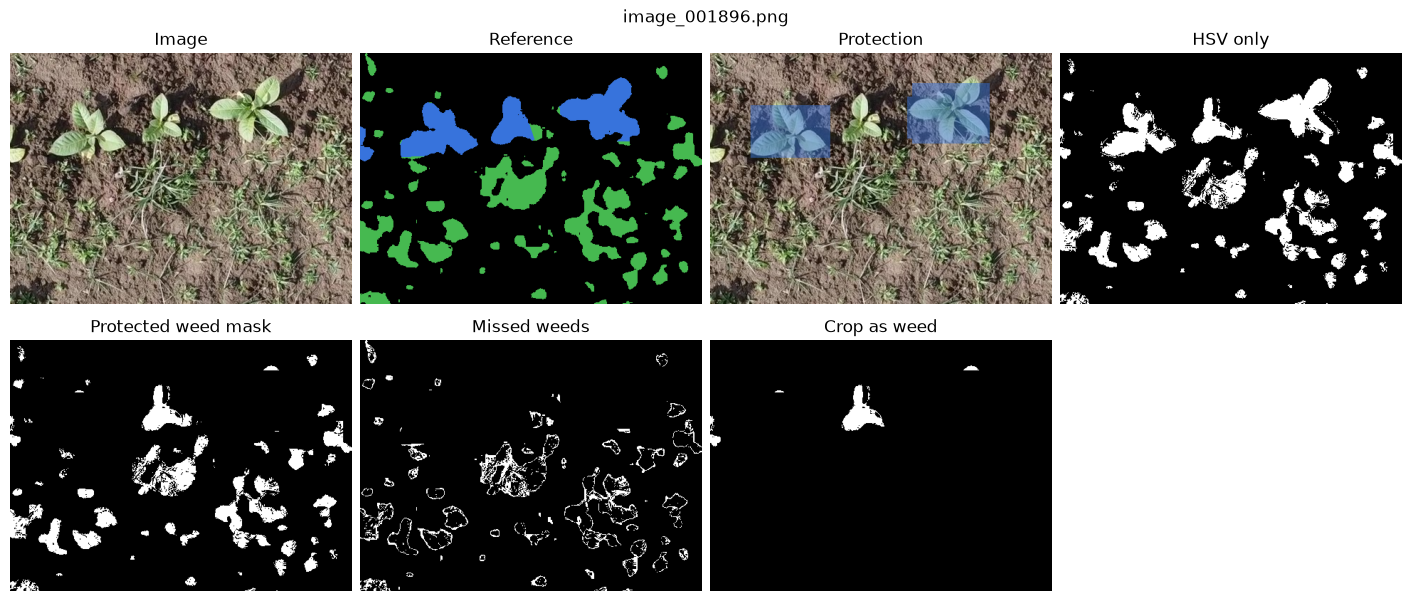

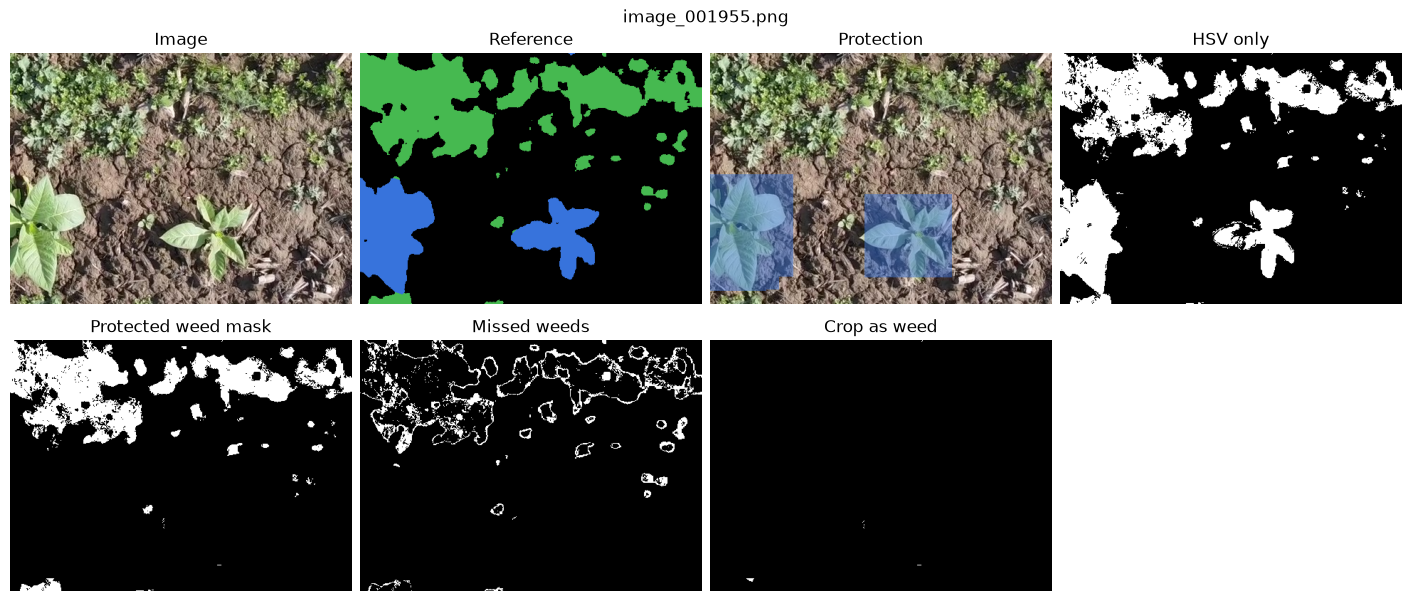

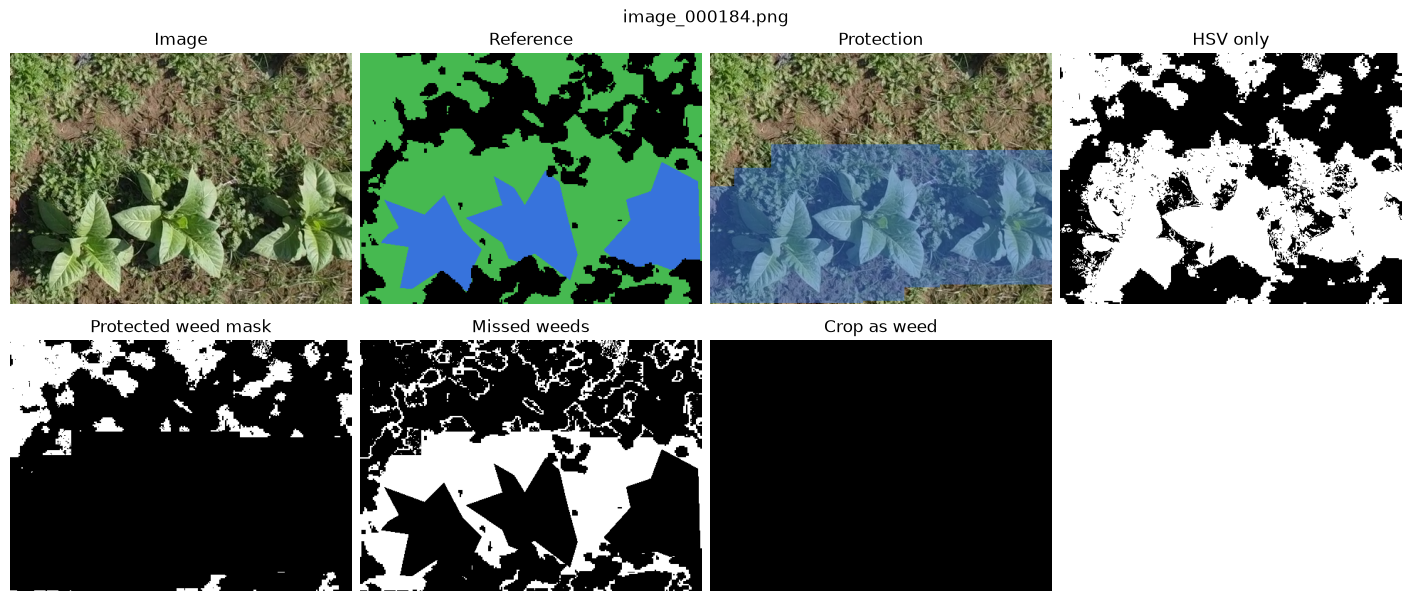

In [4]:
run_dir = None
if SAVE_RESULTS:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    run_dir = OUTPUT_ROOT / f"weed-masks-{stamp}-{uuid4().hex[:8]}"
    run_dir.mkdir(parents=True, exist_ok=False)

rows = []
for index, path in enumerate(paths):
    with Image.open(path) as image:
        rgb = np.array(image.convert("RGB"))
    with Image.open(DATASET / "semantic_masks" / (path.stem + ".png")) as image:
        truth = np.array(image)
    prediction, = predictor.predict(str(path), imgsz=IMAGE_SIZE, conf=CONFIDENCE)
    vegetation = vegetation_mask(rgb, HSV_LOWER, HSV_UPPER)
    protection = protection_mask(prediction, rgb.shape[:2], TOBACCO_ID, CONFIDENCE, PADDING_PX)
    weeds = vegetation & ~protection
    variants = [("hsv_only", vegetation, np.zeros_like(protection)),
                ("hsv_protected", weeds, protection)]
    for variant, mask, protected in variants:
        rows.append({"image": path.name, "campaign": campaigns.get(path.name, "Unknown"),
                     "variant": variant, **metric_counts(truth, mask, protected, IGNORE_LABEL)})
    if index in PREVIEW_INDICES:
        show_panel(path, rgb, truth, vegetation, protection, weeds)
    if run_dir:
        folder = run_dir / path.stem
        folder.mkdir()
        for name, mask in [("vegetation", vegetation), ("protection", protection), ("weeds", weeds)]:
            Image.fromarray(mask.astype(np.uint8) * 255).save(folder / f"{name}.png")

### Сравнение вариантов

В каждой группе сначала суммируются пиксельные счётчики. Weed IoU делит пересечение на объединение, precision — на площадь предсказанных сорняков, recall — на площадь эталонных сорняков. Для ошибок на табаке знаменатель — площадь эталонного табака, для потерь сорняков в защите — площадь эталонных сорняков. Пустой знаменатель даёт NA. Вариант HSV без защиты имеет пустую защитную область. Пиксели ignore исключаются из всех счётчиков.

In [5]:
counts = pd.DataFrame(rows)
per_image = with_metrics(counts)
terms = sorted({term for pair in METRIC_TERMS.values() for term in pair})
per_campaign = with_metrics(counts.groupby(["campaign", "variant"])[terms].sum()).reset_index()
overall = with_metrics(counts.groupby("variant")[terms].sum()).reset_index()
for table in (overall, per_campaign):
    keys = [key for key in ("campaign", "variant") if key in table]
    display(table[keys + list(METRIC_TERMS)].style.format(
        {name: "{:.4f}" for name in METRIC_TERMS}, na_rep="NA"))

if run_dir:
    for name, table in [("per_image", per_image), ("per_campaign", per_campaign), ("overall", overall)]:
        table.to_csv(run_dir / f"{name}.csv", index=False, na_rep="NA")

    def digest(path):
        with path.open("rb") as stream:
            return hashlib.file_digest(stream, "sha256").hexdigest()

    config = dict(dataset=str(DATASET), split=str(SPLIT), split_sha256=digest(SPLIT),
                  manifest_sha256=digest(manifest) if manifest.is_file() else None,
                  model=MODEL_ID, checkpoint=str(CHECKPOINT), checkpoint_sha256=digest(CHECKPOINT),
                  model_config=str(MODEL_CONFIG) if MODEL_CONFIG else None,
                  model_config_sha256=digest(MODEL_CONFIG) if MODEL_CONFIG else None,
                  device=DEVICE, image_size=IMAGE_SIZE, confidence=CONFIDENCE,
                  tobacco_id=TOBACCO_ID, padding_px=PADDING_PX, hsv_lower=HSV_LOWER,
                  hsv_upper=HSV_UPPER, ignore_label=IGNORE_LABEL, images=len(paths))
    (run_dir / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    print(f"Saved evaluation: {run_dir}")

,variant,weed_iou,weed_precision,weed_recall,crop_to_weed_error,weed_lost_in_protection,crop_outside_protection
0,hsv_only,0.4889,0.5950,0.7329,0.8044,0.0000,1.0000
1,hsv_protected,0.5413,0.8364,0.6054,0.1733,0.1763,0.2634


,campaign,variant,weed_iou,weed_precision,weed_recall,crop_to_weed_error,weed_lost_in_protection,crop_outside_protection
0,Campaign no. 1,hsv_only,0.4653,0.5899,0.6877,0.9416,0.0000,1.0000
1,Campaign no. 1,hsv_protected,0.4285,0.7371,0.5058,0.3491,0.2567,0.3673
2,Campaign no. 2,hsv_only,0.5439,0.6218,0.8128,0.6924,0.0000,1.0000
3,Campaign no. 2,hsv_protected,0.6759,0.8903,0.7373,0.0872,0.0945,0.2875
4,Campaign no. 3,hsv_only,0.4568,0.6190,0.6356,0.7275,0.0000,1.0000
5,Campaign no. 3,hsv_protected,0.5826,0.8785,0.6337,0.1630,0.0057,0.2374
6,Campaign no. 4,hsv_only,0.5153,0.6582,0.7035,0.7577,0.0000,1.0000
7,Campaign no. 4,hsv_protected,0.6987,0.9904,0.7035,0.0112,0.0007,0.0480
8,Campaign no. 5,hsv_only,0.4117,0.5437,0.6291,0.6363,0.0000,1.0000
9,Campaign no. 5,hsv_protected,0.5763,0.9984,0.5769,0.0000,0.1081,0.0027
